# 02.2 · Random forest: will a new Kindle book become popular?

**Project:** Digital Publishing Opportunity Intelligence

**Author:** Stefan Radević · Data Science Bootcamp · Capstone project

## 1. TL;DR

**Key findings**

- The random forest is better than logistic regression: **ROC AUC 0.807** (0.786), accuracy **75.7%** (74.3%), precision **66.9%** and recall **49.3%**.
- The **author's earlier books** are still the strongest sign, and **pages** matter more here, because trees can find curved effects.
- **First books** are still hard to find (recall **0.042**).

## 2. Recap

**Question.** Can we predict, from the characteristics of a book draft, whether a new Kindle book will reach at least 100 ratings in
its first 12 months on Amazon?

**From the EDA (`01_eda.ipynb`).** The table has 135,839 books published from 2019 to 2021. A book is **popular** (`popular_first_year` = 1)
if it has at least 100 estimated ratings in its first 12 months. This is 32.4% of the books. Section 9.18 of the EDA shows how the
number was chosen.

**This notebook** trains one model and compares it with a simple baseline, following the course steps: split the data, tune on
the training books only, and look at the test books once at the end.

## 3. Setup

I load the libraries and the table from the EDA. `RANDOM_STATE` makes the split and the model the same every time.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
                             roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder

PROJECT = Path("..") if Path.cwd().name == "notebooks" else Path(".")
PROCESSED = PROJECT / "data" / "processed"
RANDOM_STATE = 42
TARGET = "popular_first_year"
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#c3c2b7"
pd.set_option("display.max_columns", 30, "display.width", 200, "display.max_colwidth", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

books = pd.read_parquet(PROCESSED / "kindle_books_popularity.parquet")
print("Table:", books.shape)
print(f"Popular books: {books[TARGET].sum():,} ({books[TARGET].mean():.1%})")
books.head(3)

Table: (135839, 15)
Popular books: 44,036 (32.4%)


,parent_asin,title,author,niche,pages,title_words,is_series,self_published,author_earlier_books,publication_year,price,rating_number,first_year_reviews,first_year_ratings,popular_first_year
0,B07NDWT66X,51 Inspirational Sweet Western Romances Box Se...,Katie Wyatt,Religion & Spirituality,2845.0,18,1,0,215,2019,0.00,405,7.0,405.0,1
1,B08NRPBGGR,Back To You,Bates,Literature & Fiction,254.0,3,0,0,0,2021,6.99,38,3.0,28.5,0
2,B09L6VDZTF,The Senders of Fate: Warrior of the Dark Book 2,Garnet Hart,Literature & Fiction,312.0,10,1,1,4,2021,0.00,3,1.0,3.0,0


- The table has **135,839 books** and 15 columns.
- **44,036 books (32.4%)** are popular, so about one book in three is in the positive class.

## 4. Feature preparation

The model receives the characteristics of a draft and how it is published. Price, publication year, ratings, reviews and stars are
not used (`01_eda.ipynb`, section 11). Tree models do not need scaling or a logarithm, so I keep the original columns.

In [2]:
def prepare_features(data):
    return data.copy()


NUMERIC = ["pages", "title_words", "author_earlier_books", "is_series", "self_published"]
CATEGORICAL = ["niche"]
FEATURES = NUMERIC + CATEGORICAL
print("Features:", FEATURES)
books[FEATURES].isna().sum().to_frame("empty values").T

Features: ['pages', 'title_words', 'author_earlier_books', 'is_series', 'self_published', 'niche']


,pages,title_words,author_earlier_books,is_series,self_published,niche
empty values,6098,0,0,0,0,0


- The forest gets **6 features**. Only `pages` has empty values (6,098 books), and the pipeline fills them.

## 5. Train/test split

I keep **20% of the books for the final test**. All books of one author stay on the same side, so the test shows how the model works for
**authors it has not seen**. `StratifiedGroupKFold` does this and also keeps a similar share of popular books on both sides. It goes
one step beyond the plain `train_test_split` from the course, because a random split would put books by the same author on both sides.

In [3]:
groups = books["author"].fillna(books["parent_asin"])
X, y = books[FEATURES], books[TARGET]
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_index, test_index = next(splitter.split(X, y, groups))

X_train, X_test = X.iloc[train_index], X.iloc[test_index]
y_train, y_test = y.iloc[train_index], y.iloc[test_index]
groups_train, groups_test = groups.iloc[train_index], groups.iloc[test_index]
test_books = books.iloc[test_index].copy()

print(f"Training books: {len(X_train):,} ({y_train.mean():.1%} popular) | authors: {groups_train.nunique():,}")
print(f"Test books:     {len(X_test):,} ({y_test.mean():.1%} popular) | authors: {groups_test.nunique():,}")
print("Authors on both sides:", len(set(groups_train) & set(groups_test)))

Training books: 108,670 (32.4% popular) | authors: 64,046
Test books:     27,169 (32.4% popular) | authors: 16,017
Authors on both sides: 0


- **108,670 training books** and **27,169 test books**, each with **32.4%** popular books.
- **No author is on both sides** (0 shared authors), so the test really shows new authors.

## 6. Baseline

The baseline ignores the book and always predicts the most common answer. A model is useful only if it does better. The function
`measures` calculates the same numbers for every model.

In [4]:
def measures(name, true, probability, threshold=0.5):
    predicted = (probability >= threshold).astype(int)
    return {"model": name, "accuracy": accuracy_score(true, predicted),
            "precision": precision_score(true, predicted, zero_division=0), "recall": recall_score(true, predicted, zero_division=0),
            "f1": f1_score(true, predicted, zero_division=0), "roc_auc": roc_auc_score(true, probability)}


baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
baseline_probability = baseline.predict_proba(X_test)[:, 1]
pd.DataFrame([measures("baseline (test)", y_test, baseline_probability)]).set_index("model").round(3)

,accuracy,precision,recall,f1,roc_auc
model,,,,,
baseline (test),0.676,0.0,0.0,0.0,0.5


- The baseline always predicts "not popular". It is right for **67.6%** of the test books, but finds no popular book: precision, recall and F1 are **0**.
- Its ROC AUC is **0.5**, the same as guessing. A useful model must beat these numbers.

## 7. Candidate model

A **random forest** builds many decision trees on random parts of the data and averages their answers. It can find curved effects and
combinations of features that a straight line misses.

- The **pipeline** fills empty `pages` with the median and turns `niche` into 0/1 columns.
- I use 200 trees. `GridSearchCV` tries different limits with 5 folds and keeps authors together. `max_depth` limits how deep a tree
  grows, and `min_samples_leaf` is the smallest group of books at the end of a branch. Both reduce overfitting.

In [5]:
preprocess = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), NUMERIC),
    ("niche", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
])
pipeline = Pipeline([("prepare", preprocess),
                     ("model", RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1))])
grid = {"model__max_depth": [10, 20, None], "model__min_samples_leaf": [5, 20]}

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
search = GridSearchCV(pipeline, grid, scoring="roc_auc", cv=cv, return_train_score=True)
search.fit(X_train, y_train, groups=groups_train)
best_model = search.best_estimator_

columns = [c for c in pd.DataFrame(search.cv_results_).columns if c.startswith("param_")]
results = pd.DataFrame(search.cv_results_)[columns + ["mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"]]
results.columns = [c.replace("param_model__", "") for c in results.columns]
print("Best settings:", {k.replace("model__", ""): v for k, v in search.best_params_.items()})
print(f"Best validation ROC AUC: {search.best_score_:.4f}")
results.sort_values("rank_test_score").round(4)

Best settings: {'max_depth': None, 'min_samples_leaf': 20}
Best validation ROC AUC: 0.7993


,max_depth,min_samples_leaf,mean_train_score,mean_test_score,std_test_score,rank_test_score
5,None,20,0.8296,0.7993,0.0036,1
3,20,20,0.8283,0.7993,0.0035,2
0,10,5,0.8148,0.7969,0.0032,3
2,20,5,0.8765,0.7965,0.0032,4
1,10,20,0.8089,0.7963,0.0033,5
4,None,5,0.8919,0.7938,0.0029,6


- The best combination is **no depth limit with `min_samples_leaf` = 20**, with a validation ROC AUC of **0.7993**. A depth of 20 gives almost the same result.
- With leaves of only 5 books and no depth limit the training score rises to 0.8919, but validation falls to 0.7938. This is **overfitting**.
- The chosen forest still has a gap: 0.8296 in training against 0.7993 in validation.

## 8. Evaluation

Now I use the **test books once**. I compare training and test results with the baseline. If the model were much better on training
books, it would be overfitting. I use a threshold of 0.5: a probability of 0.5 or more means "popular".

In [6]:
train_probability = best_model.predict_proba(X_train)[:, 1]
test_probability = best_model.predict_proba(X_test)[:, 1]
test_predicted = (test_probability >= 0.5).astype(int)
scores = pd.DataFrame([measures("baseline (test)", y_test, baseline_probability),
                       measures("Random forest (train)", y_train, train_probability),
                       measures("Random forest (test)", y_test, test_probability)]).set_index("model")
scores.round(3)

,accuracy,precision,recall,f1,roc_auc
model,,,,,
baseline (test),0.676,0.000,0.000,0.000,0.500
Random forest (train),0.771,0.693,0.526,0.598,0.830
Random forest (test),0.757,0.669,0.493,0.568,0.807


- On the test books the forest is better than the baseline and logistic regression: accuracy **0.757** (0.743), precision **0.669** (0.654), recall **0.493** (0.439), F1 **0.568** (0.525) and ROC AUC **0.807** (0.786).
- Training ROC AUC (0.830) is higher than test (0.807), so there is some overfitting.

The **confusion matrix** counts correct answers and the two kinds of errors. The **ROC curve** shows how well the model ranks books at every
threshold; the dashed line is guessing.

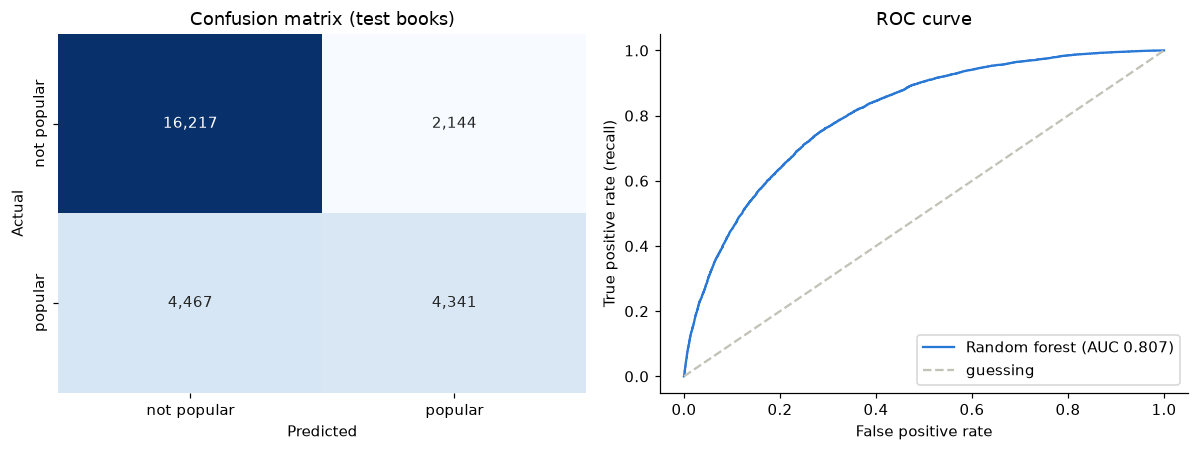

In [7]:
matrix = confusion_matrix(y_test, test_predicted)
fpr, tpr, _ = roc_curve(y_test, test_probability)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
sns.heatmap(matrix, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["not popular", "popular"], yticklabels=["not popular", "popular"])
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")
axes[0].set_title("Confusion matrix (test books)")
axes[1].plot(fpr, tpr, color=BLUE, label=f"Random forest (AUC {roc_auc_score(y_test, test_probability):.3f})")
axes[1].plot([0, 1], [0, 1], color=GREY, linestyle="--", label="guessing")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate (recall)")
axes[1].set_title("ROC curve")
axes[1].legend()
plt.tight_layout()
plt.show()

- The forest correctly finds **4,341** of the 8,808 popular books (3,865 for logistic regression) and misses **4,467**.
- It raises **2,144** false alarms, a little more than logistic regression (2,042).

The **threshold** can be changed. A lower one finds more popular books but raises more false alarms. The second table checks whether the
probabilities can be read as chances: within each probability range I compare the average prediction with the real share of popular
books.

In [8]:
rows = []
for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:
    row = measures(threshold, y_test, test_probability, threshold)
    row["books called popular"] = int((test_probability >= threshold).sum())
    rows.append(row)
threshold_table = pd.DataFrame(rows).rename(columns={"model": "threshold"}).set_index("threshold").drop(columns="roc_auc")

ranges = pd.cut(test_probability, np.linspace(0, 1, 11), include_lowest=True)
reliability = pd.DataFrame({"probability": test_probability, "actual": y_test.to_numpy()}).groupby(ranges, observed=True).agg(
    books=("actual", "size"), predicted_pct=("probability", lambda s: s.mean() * 100), actual_pct=("actual", lambda s: s.mean() * 100))
display(threshold_table.round(3))
reliability.round(1)

,accuracy,precision,recall,f1,books called popular
threshold,,,,,
0.3,0.706,0.530,0.800,0.638,13282
0.4,0.746,0.598,0.655,0.625,9651
0.5,0.757,0.669,0.493,0.568,6485
0.6,0.740,0.741,0.304,0.431,3611
0.7,0.706,0.820,0.119,0.208,1277


,books,predicted_pct,actual_pct
"(-0.001, 0.1]",5182,5.6,5.0
"(0.1, 0.2]",4664,14.8,11.8
"(0.2, 0.3]",4041,25.0,23.6
"(0.3, 0.4]",3631,35.0,35.0
"(0.4, 0.5]",3166,44.8,45.2
"(0.5, 0.6]",2874,54.9,58.0
"(0.6, 0.7]",2334,64.6,69.8
"(0.7, 0.8]",1248,73.7,82.2
"(0.8, 0.9]",29,81.5,72.4


- At **0.3** the forest finds **80.0%** of the popular books with a precision of 53.0%. At **0.7** it is right **82.0%** of the time but finds only 11.9%.
- F1 is highest at 0.3 (0.638). I keep 0.5 for the comparison.
- Probabilities are mostly close to the real shares. From 0.7 to 0.8 the forest is too careful (73.7% predicted, 82.2% real). The range 0.8 to 0.9 has only 29 books.

## 9. Error analysis

Where does the model do well or badly? I compare groups of test books. `actual_%` is the real share of popular books and `predicted_%` is the
share the model calls popular.

In [9]:
test_books["probability"] = test_probability
test_books["predicted"] = test_predicted
test_books["route"] = np.where(test_books["self_published"] == 1, "self-published", "publisher")
test_books["experience"] = pd.cut(test_books["author_earlier_books"], [-1, 0, 2, 9, np.inf],
                                  labels=["first book", "1-2 earlier", "3-9 earlier", "10+ earlier"])


def group_report(column, minimum=300):
    rows = []
    for group, part in test_books.groupby(column, observed=True):
        if len(part) >= minimum and part[TARGET].nunique() == 2:
            rows.append({column: group, "books": len(part), "actual_%": part[TARGET].mean() * 100, "predicted_%": part["predicted"].mean() * 100,
                         "precision": precision_score(part[TARGET], part["predicted"], zero_division=0),
                         "recall": recall_score(part[TARGET], part["predicted"], zero_division=0),
                         "roc_auc": roc_auc_score(part[TARGET], part["probability"])})
    return pd.DataFrame(rows).set_index(column)


display(group_report("route").round(3))
display(group_report("experience").round(3))
niche_report = group_report("niche").sort_values("recall", ascending=False)
pd.concat([niche_report.head(4), niche_report.tail(4)]).round(3)

,books,actual_%,predicted_%,precision,recall,roc_auc
route,,,,,,
publisher,9991,46.912,36.823,0.693,0.544,0.742
self-published,17178,23.990,16.335,0.639,0.435,0.812


,books,actual_%,predicted_%,precision,recall,roc_auc
experience,,,,,,
first book,8411,13.042,0.951,0.575,0.042,0.764
1-2 earlier,4712,20.947,2.950,0.576,0.081,0.741
3-9 earlier,5729,32.798,11.032,0.581,0.195,0.697
10+ earlier,8317,58.254,67.741,0.683,0.794,0.702


,books,actual_%,predicted_%,precision,recall,roc_auc
niche,,,,,,
"Cookbooks, Food & Wine",340,24.118,24.706,0.619,0.634,0.823
Romance,3112,47.943,44.087,0.660,0.607,0.716
Literature & Fiction,10025,35.641,31.012,0.667,0.581,0.804
"Mystery, Thriller & Suspense",1701,40.682,32.040,0.690,0.543,0.779
Biographies & Memoirs,606,23.432,6.106,0.568,0.148,0.817
Children's eBooks,1853,15.704,2.105,0.795,0.107,0.814
Education & Teaching,428,13.084,0.000,0.000,0.000,0.811
Business & Money,988,12.449,0.000,0.000,0.000,0.750


- **Route:** recall is **0.435** for self-published books (logistic regression 0.292) and 0.544 for publisher books.
- **Experience:** recall for first books rises only to **0.042**, while it is 0.794 for authors with 10+ earlier books.
- **Niches:** Cookbooks (0.634) and Romance (0.607) have high recall. **Education & Teaching** and **Business & Money** have recall **0**: no probability there passes 0.5, although the ROC AUC is 0.811 and 0.750.

I also look at the books where the model was most confident and wrong.

In [10]:
show = ["title", "niche", "pages", "is_series", "self_published", "author_earlier_books", "first_year_ratings", "probability"]
false_alarms = test_books[(test_books["predicted"] == 1) & (test_books[TARGET] == 0)].nlargest(5, "probability")[show]
missed = test_books[(test_books["predicted"] == 0) & (test_books[TARGET] == 1)].nsmallest(5, "probability")[show]
display(false_alarms.round(2))
display(missed.round(2))
print("Missed popular books:", f"{((test_books['predicted'] == 0) & (test_books[TARGET] == 1)).sum():,}",
      "| self-published:", f"{test_books.loc[(test_books['predicted'] == 0) & (test_books[TARGET] == 1), 'self_published'].mean():.1%}",
      "| median earlier books:", test_books.loc[(test_books['predicted'] == 0) & (test_books[TARGET] == 1), 'author_earlier_books'].median())

,title,niche,pages,is_series,self_published,author_earlier_books,first_year_ratings,probability
34145,An Unwilling Conquest (Lester Family Book 2),Romance,319.0,1,0,110,0.0,0.83
5021,Fair Juno: A Regency Romance (Historical Book 13),Romance,304.0,1,0,102,0.0,0.83
32913,Wicked Witches of Midtown: Paranormal in Manha...,Literature & Fiction,384.0,0,1,28,12.5,0.83
116458,Unconfessed Desires of a Bluestocking: A Steam...,Literature & Fiction,450.0,0,1,27,95.0,0.82
13636,Hayashi's Hero: A Paranormal Multipartner Shif...,Romance,236.0,1,0,94,22.0,0.82


,title,niche,pages,is_series,self_published,author_earlier_books,first_year_ratings,probability
127255,Oodles and Oodles of Noodley Noodles,Literature & Fiction,17.0,0,1,0,286.85,0.01
125812,Oh Deer!,Children's eBooks,32.0,0,1,0,141.87,0.02
76280,Henrietta’s Thistleberry Boots,Children's eBooks,NaN,0,1,0,111.00,0.02
124248,Nothing About Business: Short Stories From Eve...,Business & Money,118.0,0,1,0,124.00,0.02
18267,Trip Trap Trouble (Fairytale Fraud),Children's eBooks,39.0,0,1,0,174.20,0.02


Missed popular books: 4,467 | self-published: 52.1% | median earlier books: 3.0


- **False alarms:** the most confident ones have 236 to 450 pages and authors with 27 to 110 earlier books, but only 0 to 95 first-year ratings.
- **Missed books:** the most confident ones are short self-published first books, three of them children's books, with 111 to 287 first-year ratings.
- Of the **4,467** missed popular books, **52.1%** are self-published, and their median author has 3 earlier books.

## 10. Interpretation

**Permutation importance** shuffles one feature in the test books and measures how much the ROC AUC falls. A large fall means the model relies
on that feature. I use 8,000 test books to keep this quick.

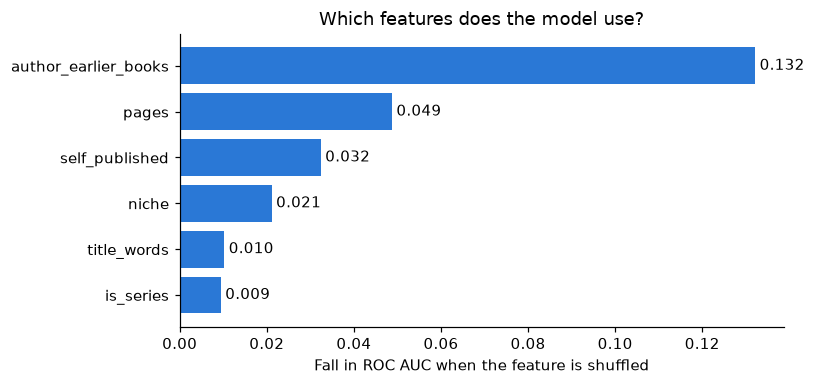

In [11]:
sample = X_test.sample(8000, random_state=RANDOM_STATE)
importance = permutation_importance(best_model, sample, y_test.loc[sample.index], scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE)
importance_table = pd.Series(importance.importances_mean, index=FEATURES, name="fall in ROC AUC").sort_values()

fig, ax = plt.subplots(figsize=(7.5, 3.6))
bars = ax.barh(importance_table.index, importance_table.values, color=BLUE)
ax.bar_label(bars, fmt="%.3f", padding=3)
ax.set_xlabel("Fall in ROC AUC when the feature is shuffled")
ax.set_title("Which features does the model use?")
plt.tight_layout()
plt.show()

- The **author's earlier books** are by far the most important (**0.132**).
- **Pages** come next (**0.049**), then **self-published** (0.032) and **niche** (0.021). **Title words** (0.010) and **series** (0.009) add little.

A tree model has no simple weights, so I look at its behaviour. I take 3,000 training books, give all of them the same value of one feature,
and average the predicted chance. This is called **partial dependence**.

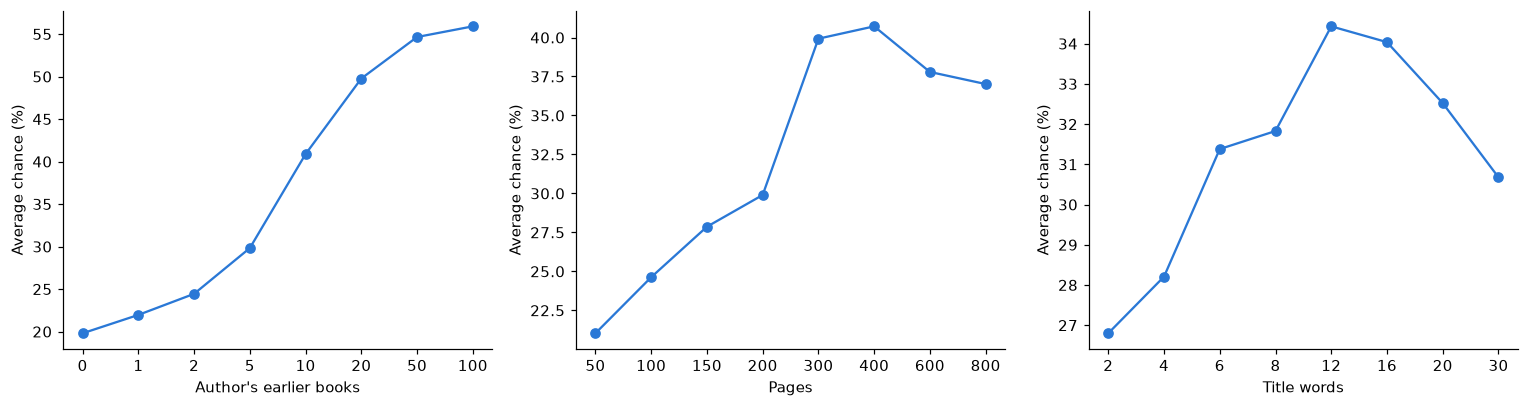

Author's earlier books {0: 19.8, 1: 22.0, 2: 24.4, 5: 29.8, 10: 40.9, 20: 49.8, 50: 54.7, 100: 55.9}
Pages {50: 21.0, 100: 24.6, 150: 27.9, 200: 29.9, 300: 39.9, 400: 40.7, 600: 37.8, 800: 37.0}
Title words {2: 26.8, 4: 28.2, 6: 31.4, 8: 31.8, 12: 34.4, 16: 34.0, 20: 32.5, 30: 30.7}
Series: no 29.7 | yes 35.6


Publisher 38.2 | self-published 28.8


In [12]:
reference = X_train.sample(3000, random_state=RANDOM_STATE)


def average_chance(column, values):
    return pd.Series([best_model.predict_proba(reference.assign(**{column: value}))[:, 1].mean() * 100 for value in values],
                     index=values, name="average chance %")


effects = [("author_earlier_books", [0, 1, 2, 5, 10, 20, 50, 100], "Author's earlier books"),
           ("pages", [50, 100, 150, 200, 300, 400, 600, 800], "Pages"), ("title_words", [2, 4, 6, 8, 12, 16, 20, 30], "Title words")]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
tables = {}
for ax, (column, values, label) in zip(axes, effects):
    tables[label] = average_chance(column, values)
    ax.plot(range(len(values)), tables[label].values, marker="o", color=BLUE)
    ax.set_xticks(range(len(values)), values)
    ax.set_xlabel(label)
    ax.set_ylabel("Average chance (%)")
plt.tight_layout()
plt.show()
for label, table in tables.items():
    print(label, table.round(1).to_dict())
print("Series: no", round(average_chance("is_series", [0]).iloc[0], 1), "| yes", round(average_chance("is_series", [1]).iloc[0], 1))
print("Publisher", round(average_chance("self_published", [0]).iloc[0], 1), "| self-published", round(average_chance("self_published", [1]).iloc[0], 1))

- **Earlier books:** the average chance rises from **19.8%** for a first book to **40.9%** with 10 earlier books and **55.9%** with 100. The rise slows after about 20 books.
- **Pages:** it rises from **21.0%** at 50 pages to **40.7%** at 400, then falls to 37.0% at 800.
- **Title words:** it is highest around 12 words (34.4%), but the differences are small.
- **Series** gives 35.6% against 29.7%, and a **publisher** 38.2% against 28.8% for self-published books.
- These are patterns in the model, not proof that a change would cause the same result.

Finally I give the model a few **invented book drafts** to see the estimated chance of reaching 100 ratings in the first year. All have 250 pages and
an 8-word title unless the description says otherwise.

In [13]:
examples = pd.DataFrame([
    ["Romance, self-published first book", "Romance", 250, 8, 0, 1, 0],
    ["Same book in a series", "Romance", 250, 8, 1, 1, 0],
    ["In a series, author has 10 earlier books", "Romance", 250, 8, 1, 1, 10],
    ["First book with a publisher", "Romance", 250, 8, 0, 0, 0],
    ["First book, 400 pages", "Romance", 400, 8, 0, 1, 0],
    ["Education, self-published first book", "Education & Teaching", 250, 8, 0, 1, 0],
], columns=["draft", "niche", "pages", "title_words", "is_series", "self_published", "author_earlier_books"])
examples["chance of 100+ ratings %"] = best_model.predict_proba(prepare_features(examples)[FEATURES])[:, 1] * 100
examples.drop(columns=["title_words"]).round(1)

,draft,niche,pages,is_series,self_published,author_earlier_books,chance of 100+ ratings %
0,"Romance, self-published first book",Romance,250,0,1,0,17.3
1,Same book in a series,Romance,250,1,1,0,20.7
2,"In a series, author has 10 earlier books",Romance,250,1,1,10,52.6
3,First book with a publisher,Romance,250,0,0,0,30.1
4,"First book, 400 pages",Romance,400,0,1,0,21.1
5,"Education, self-published first book",Education & Teaching,250,0,1,0,7.2


- A self-published first Romance book has an estimated chance of **17.3%**; in a series **20.7%**; in a series by an author with 10 earlier books **52.6%**.
- With a publisher the first book has **30.1%**, and with 400 pages **21.1%**. In Education & Teaching it has **7.2%**.
- These are **associations, not promises**.

## 11. Limitations & ethics

**Limitations**

- **The target is estimated.** First-year ratings come from dated reviews scaled to Amazon's total ratings, so books close to 100 can fall on the wrong side.
- **Ratings are not sales.** The model predicts reader response, not copies sold or income.
- **Only books with at least one review in the file are included**, so real chances for a new book are probably lower.
- `self_published` comes from my rule, and `author_earlier_books` counts only books in this catalog. Some "authors" are really companies.
- Marketing, cover, writing quality and reviews are not in the data.
- The model was built on books from 2019–2021, so it may not hold for later years.
- The results show **associations, not causes**.

**Ethics**

- The model favours experienced authors. It should not decide which authors or books deserve support.
- It is meant as **information for an author**. A low chance does not mean that a book is bad.

## 12. Conclusion

I save the test predictions and the main results for the comparison notebook.

In [14]:
output = test_books[["parent_asin", TARGET, "niche", "self_published", "author_earlier_books", "probability", "predicted"]]
output.to_parquet(PROCESSED / "predictions_popularity_random_forest.parquet", index=False)
summary = {"model": "Random forest", "best_params": {k.replace("model__", ""): v for k, v in search.best_params_.items()},
           "cv_roc_auc": float(search.best_score_), "cv_std": float(search.cv_results_["std_test_score"][search.best_index_]),
           "train_roc_auc": float(roc_auc_score(y_train, train_probability)),
           "importance": {k: float(v) for k, v in importance_table.sort_values(ascending=False).items()}}
(PROCESSED / "results_popularity_random_forest.json").write_text(json.dumps(summary, indent=2, default=str), encoding="utf-8")
print("Saved predictions:", output.shape)

Saved predictions: (27169, 7)


**What worked.** The forest beats the baseline and logistic regression (ROC AUC 0.807 against 0.786) and shows curved effects, especially for length.

**What did not work.** It overfits to some degree, is harder to explain and still finds few popular first books (recall 0.042).

**Next.** **02.3 Gradient boosting** has to beat ROC AUC **0.807** on the same test books.